[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!



----- MENU -----
1. Detect Language
2. Word Count
3. Sentence Count
4. Show Word Tokens
5. Show Sentence Tokens
6. Visualize Word Count vs Sentence Count
7. Exit

Enter your choice: 1

Language: en

Enter your choice: 2

Word Count: 380

Enter your choice: 3

Sentence Count: 10

Enter your choice: 4

First 20 Word Tokens:
['One', 'of', 'the', 'other', 'reviewers', 'has', 'mentioned', 'that', 'after', 'watching', 'just', '1', 'Oz', 'episode', 'you', "'ll", 'be', 'hooked', '.', 'They']

Enter your choice: 5

First 5 Sentence Tokens:
["One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked.", 'They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO.', 'Trust me, this is not a show for the faint hearted or timid.', 'This show pulls no punches with regards to drugs, sex or violence.', 'Its is hardcore, in the

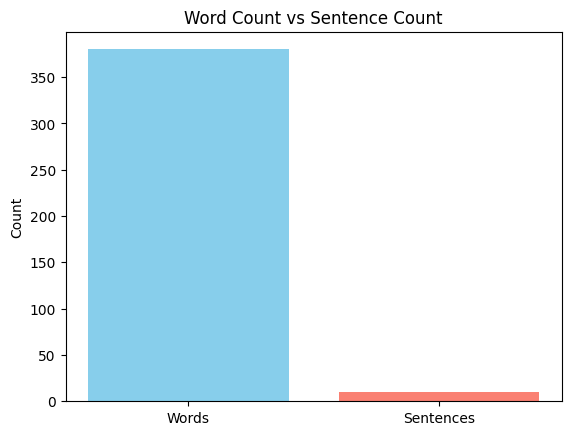


Enter your choice: 7

Exiting...


In [ ]:
import pandas as pd
import nltk
import matplotlib.pyplot as plt
from langdetect import detect
from nltk.tokenize import word_tokenize, sent_tokenize

nltk.download('punkt')
nltk.download('punkt_tab')

df = pd.read_csv("IMDB Dataset.csv", on_bad_lines='skip', engine='python')

text = str(df["review"].iloc[0])
sentiment = df["sentiment"].iloc[0]

words = word_tokenize(text)
sentences = sent_tokenize(text)

print("\n----- MENU -----")
print("1. Detect Language")
print("2. Word Count")
print("3. Sentence Count")
print("4. Show Word Tokens")
print("5. Show Sentence Tokens")
print("6. Visualize Word Count vs Sentence Count")
print("7. Exit")

while True:
    choice = int(input("\nEnter your choice: "))

    if choice == 1:
        print("\nLanguage:", detect(text))

    elif choice == 2:
        print("\nWord Count:", len(words))

    elif choice == 3:
        print("\nSentence Count:", len(sentences))

    elif choice == 4:
      print("\nFirst 20 Word Tokens:")
      print(words[:20])

    elif choice == 5:
        print("\nFirst 5 Sentence Tokens:")
        print(sentences[:5])

    elif choice == 6:
        plt.bar(
            ["Words", "Sentences"],
            [len(words), len(sentences)],
            color=["skyblue", "salmon"]
        )
        plt.title("Word Count vs Sentence Count")
        plt.ylabel("Count")
        plt.show()

    elif choice == 7:
        print("\nExiting...")
        break

    else:
        print("\nInvalid choice, try again.")

In [ ]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!



----- MENU -----
1. Show Sample Words
2. Perform Stemming
3. Perform Lemmatization
4. Compare Stemming vs Lemmatization
5. Visualize Unique Word Counts
6. Exit

Enter your choice: 1

Sample Words:
['One', 'of', 'the', 'other', 'reviewers', 'has', 'mentioned', 'that', 'after', 'watching', 'just', 'Oz', 'episode', 'you', 'be', 'hooked', 'They', 'are', 'right', 'as', 'this', 'is', 'exactly', 'what', 'happened', 'with', 'br', 'br', 'The', 'first']

Enter your choice: 2

Stemming:
One -> one
of -> of
the -> the
other -> other
reviewers -> review
has -> ha
mentioned -> mention
that -> that
after -> after
watching -> watch
just -> just
Oz -> oz
episode -> episod
you -> you
be -> be
hooked -> hook
They -> they
are -> are
right -> right
as -> as
this -> thi
is -> is
exactly -> exactli
what -> what
happened -> happen
with -> with
br -> br
br -> br
The -> the
first -> first

Enter your choice: 3

Lemmatization:
One -> One
of -> of
the -> the
other -> other
reviewers -> reviewers
has -> have
ment

,Word,Stem,Lemma
0,One,one,One
1,of,of,of
2,the,the,the
3,other,other,other
4,reviewers,review,reviewers
5,has,ha,have
6,mentioned,mention,mention
7,that,that,that
8,after,after,after
9,watching,watch,watch



Enter your choice: 5


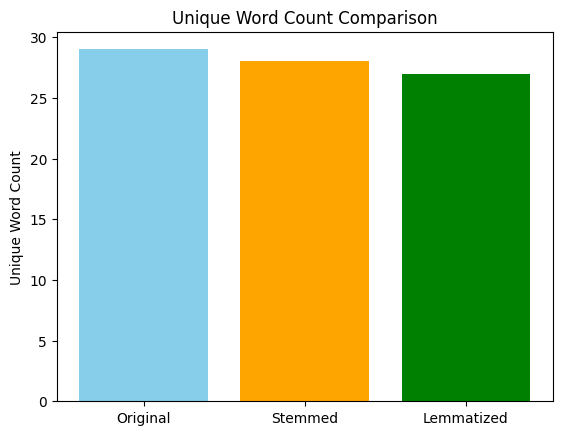


Enter your choice: 6

Exiting...


In [ ]:
import pandas as pd
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

df = pd.read_csv("IMDB Dataset.csv", on_bad_lines='skip', engine='python')

text = str(df["review"].iloc[0])
words = [w for w in word_tokenize(text) if w.isalpha()][:30]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

print("\n----- MENU -----")
print("1. Show Sample Words")
print("2. Perform Stemming")
print("3. Perform Lemmatization")
print("4. Compare Stemming vs Lemmatization")
print("5. Visualize Unique Word Counts")
print("6. Exit")

while True:
    choice = int(input("\nEnter your choice: "))

    if choice == 1:
        print("\nSample Words:")
        print(words)

    elif choice == 2:
        print("\nStemming:")
        for w in words:
            print(w, "->", stemmer.stem(w))

    elif choice == 3:
        print("\nLemmatization:")
        for w in words:
            print(w, "->", lemmatizer.lemmatize(w, pos='v'))

    elif choice == 4:
        print("\n----- STEMMING VS LEMMATIZATION -----")

        comparison = pd.DataFrame({
            "Word": words,
            "Stem": [stemmer.stem(w) for w in words],
            "Lemma": [lemmatizer.lemmatize(w, pos='v') for w in words]
        })

        display(comparison)

    elif choice == 5:
        original_unique = len(set(words))
        stemmed_unique = len(set(stemmer.stem(w) for w in words))
        lemmatized_unique = len(set(lemmatizer.lemmatize(w, pos='v') for w in words))

        plt.bar(
            ["Original", "Stemmed", "Lemmatized"],
            [original_unique, stemmed_unique, lemmatized_unique],
            color=["skyblue", "orange", "green"]
        )

        plt.title("Unique Word Count Comparison")
        plt.ylabel("Unique Word Count")
        plt.show()

    elif choice == 6:
        print("\nExiting...")
        break

    else:
        print("\nInvalid choice, try again.")

In [ ]:
!pip install gensim

import pandas as pd
import nltk
import numpy as np
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from gensim.models import Word2Vec
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('stopwords')

df = pd.read_csv("IMDB Dataset.csv", on_bad_lines='skip', engine='python')

sample = df.sample(300, random_state=42).reset_index(drop=True)

stop_words = set(stopwords.words('english'))

text = str(sample["review"].iloc[0])
tagged_words = nltk.pos_tag(word_tokenize(text)[:30])

all_tokens = []

for review in sample["review"]:
    tokens = [
        w.lower()
        for w in word_tokenize(str(review))
        if w.isalpha() and w.lower() not in stop_words
    ]
    all_tokens.append(tokens)

w2v_model = None
accuracy = None

print("\n----- MENU -----")
print("1. Show POS Tags")
print("2. Train Word Embeddings")
print("3. Text Classification")
print("4. Exit")

while True:

    choice = int(input("\nEnter your choice: "))

    if choice == 1:
        print("\n----- POS TAGGING -----")

        pos_data = pd.DataFrame({
            "Word": [word for word, tag in tagged_words],
            "POS Tag": [tag for word, tag in tagged_words]
        })

        display(pos_data)

    elif choice == 2:
        print("\n----- WORD EMBEDDINGS -----")

        w2v_model = Word2Vec(
            sentences=all_tokens,
            vector_size=100,
            window=5,
            min_count=2,
            workers=2,
            seed=42
        )

        print("Word2Vec model trained successfully.")
        print("Vocabulary Size:", len(w2v_model.wv.index_to_key))

    elif choice == 3:
        if w2v_model is None:
            print("\nPlease train Word2Vec first using option 2.")
            continue

        print("\n----- TEXT CLASSIFICATION -----")

        X = []

        for tokens in all_tokens:

            vectors = [
                w2v_model.wv[word]
                for word in tokens
                if word in w2v_model.wv
            ]

            if vectors:
                X.append(np.mean(vectors, axis=0))
            else:
                X.append(np.zeros(100))

        X = np.array(X)

        y = np.array([
            1 if sentiment == "positive" else 0
            for sentiment in sample["sentiment"]
        ])

        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=42
        )

        model = LogisticRegression(max_iter=1000)

        model.fit(X_train, y_train)

        predictions = model.predict(X_test)

        accuracy = accuracy_score(y_test, predictions)

        print("Classification Accuracy:", round(accuracy, 3))

    elif choice == 4:
        print("\nExiting...")
        break

    else:
        print("\nInvalid choice, try again.")

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!



----- MENU -----
1. Show POS Tags
2. Train Word Embeddings
3. Text Classification
4. Exit

Enter your choice: 1

----- POS TAGGING -----


,Word,POS Tag
0,I,PRP
1,just,RB
2,saw,VBD
3,this,DT
4,movie,NN
5,(,(
6,mainly,RB
7,because,IN
8,Brady,NNP
9,Corbet,NNP



Enter your choice: 2

----- WORD EMBEDDINGS -----
Word2Vec model trained successfully.
Vocabulary Size: 3833

Enter your choice: 3

----- TEXT CLASSIFICATION -----
Classification Accuracy: 0.633

Enter your choice: 4

Exiting...


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!



----- MENU -----
1. POS Tagging
2. Word Embeddings
3. Text Classification
4. Exit

Enter your choice: 1

----- POS TAGGING -----


,Word,POS Tag
0,I,PRP
1,just,RB
2,saw,VBD
3,this,DT
4,movie,NN
5,(,(
6,mainly,RB
7,because,IN
8,Brady,NNP
9,Corbet,NNP



Enter your choice: 2

----- WORD EMBEDDINGS -----
Word2Vec model trained successfully.

Sample Word Embeddings:

 br ->
[ 0.25279227 -0.06048215 -0.28790253  0.09896778 -0.39473185  0.469697
  0.5569602   0.54222584 -0.21297204 -0.15789773]

 movie ->
[ 0.22081235 -0.06197873 -0.23539     0.07039006 -0.31848496  0.38930243
  0.47882447  0.4501342  -0.17341444 -0.121842  ]

 film ->
[ 0.2088081  -0.04692699 -0.2382977   0.0843745  -0.32080245  0.37286896
  0.47177154  0.44966546 -0.17418578 -0.11899824]

 one ->
[ 0.17495148 -0.03942532 -0.21038625  0.07574398 -0.2672613   0.3093974
  0.3871179   0.37029493 -0.14565049 -0.11319309]

 like ->
[ 0.1676803  -0.03516725 -0.18191469  0.06872089 -0.23934859  0.28309944
  0.34820393  0.32137862 -0.11788466 -0.10450243]

Enter your choice: 3

----- TEXT CLASSIFICATION -----


,Actual,Predicted
0,0,1
1,0,0
2,1,1
3,0,0
4,1,1
5,1,0
6,1,1
7,0,1
8,1,1
9,1,1


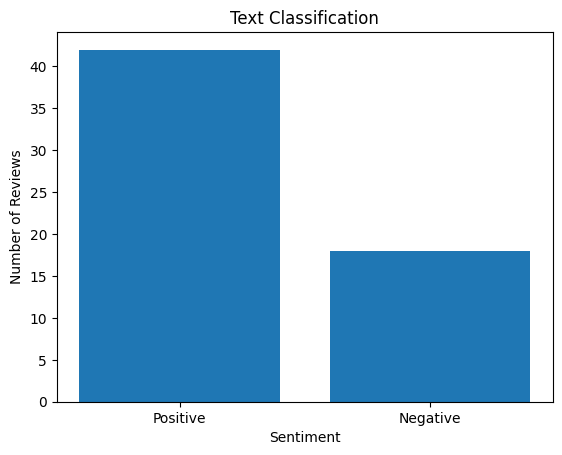


Enter your choice: 4

Exiting...


In [ ]:
!pip install gensim

import pandas as pd
import nltk
import numpy as np
import matplotlib.pyplot as plt

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from gensim.models import Word2Vec

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('stopwords')

df = pd.read_csv("IMDB Dataset.csv", on_bad_lines='skip', engine='python')

sample = df.sample(300, random_state=42).reset_index(drop=True)

stop_words = set(stopwords.words('english'))

text = str(sample["review"].iloc[0])

tagged_words = nltk.pos_tag(
    word_tokenize(text)[:30]
)

all_tokens = []

for review in sample["review"]:

    tokens = [
        word.lower()
        for word in word_tokenize(str(review))
        if word.isalpha() and word.lower() not in stop_words
    ]

    all_tokens.append(tokens)

w2v_model = None

print("\n----- MENU -----")
print("1. POS Tagging")
print("2. Word Embeddings")
print("3. Text Classification")
print("4. Exit")

while True:

    choice = int(input("\nEnter your choice: "))

    if choice == 1:

        print("\n----- POS TAGGING -----")

        pos_data = pd.DataFrame({
            "Word": [word for word, tag in tagged_words],
            "POS Tag": [tag for word, tag in tagged_words]
        })

        display(pos_data)

    elif choice == 2:

        print("\n----- WORD EMBEDDINGS -----")

        w2v_model = Word2Vec(
            sentences=all_tokens,
            vector_size=100,
            window=5,
            min_count=2,
            workers=2,
            seed=42
        )

        print("Word2Vec model trained successfully.")
        print("\nSample Word Embeddings:")

        words = w2v_model.wv.index_to_key[:5]

        for word in words:
            print("\n", word, "->")
            print(w2v_model.wv[word][:10])

    elif choice == 3:

        if w2v_model is None:
            print("\nPlease perform Word Embeddings first using option 2.")
            continue

        print("\n----- TEXT CLASSIFICATION -----")

        X = []

        for tokens in all_tokens:

            vectors = [
                w2v_model.wv[word]
                for word in tokens
                if word in w2v_model.wv
            ]

            if vectors:
                X.append(np.mean(vectors, axis=0))
            else:
                X.append(np.zeros(100))

        X = np.array(X)

        y = np.array([
            1 if sentiment == "positive" else 0
            for sentiment in sample["sentiment"]
        ])

        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=42
        )

        model = LogisticRegression(max_iter=1000)

        model.fit(X_train, y_train)

        predictions = model.predict(X_test)

        result = pd.DataFrame({
            "Actual": y_test,
            "Predicted": predictions
        })

        display(result.head(20))

        counts = pd.Series(predictions).map({
            1: "Positive",
            0: "Negative"
        }).value_counts()

        plt.bar(counts.index, counts.values)

        plt.title("Text Classification")
        plt.xlabel("Sentiment")
        plt.ylabel("Number of Reviews")

        plt.show()

    elif choice == 4:

        print("\nExiting...")
        break

    else:

        print("\nInvalid choice.")

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package maxent_ne_chunker_tab to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping chunkers/maxent_ne_chunker_tab.zip.
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Unzipping corpora/words.zip.



----- MENU -----
1. Show Named Entities
2. Visualize Entity Type Distribution
3. Exit

Enter your choice: 1

----- NAMED ENTITIES -----
Oz -> PERSON
Oswald Maximum -> ORGANIZATION
Security -> ORGANIZATION
Emerald City -> PERSON
Em City -> PERSON
Muslims -> PERSON
Latinos -> GPE
Christians -> GPE
Italians -> GPE
Irish -> GPE

Enter your choice: 2

----- ENTITY TYPE DISTRIBUTION -----


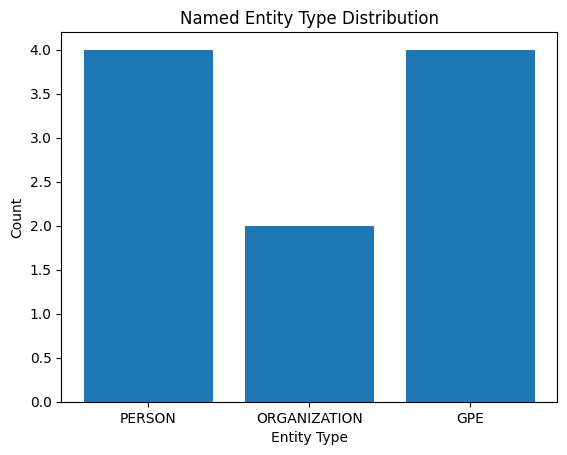


Enter your choice: 3

Exiting...


In [ ]:
import pandas as pd
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from collections import Counter

nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('maxent_ne_chunker_tab')
nltk.download('words')

df = pd.read_csv(
    "IMDB Dataset.csv",
    on_bad_lines='skip',
    engine='python'
)

text = str(df["review"].iloc[0])

tagged = nltk.pos_tag(
    word_tokenize(text)
)

tree = nltk.ne_chunk(tagged)

print("\n----- MENU -----")
print("1. Show Named Entities")
print("2. Visualize Entity Type Distribution")
print("3. Exit")

while True:

    choice = int(input("\nEnter your choice: "))

    if choice == 1:

        print("\n----- NAMED ENTITIES -----")

        found = False

        for subtree in tree:

            if hasattr(subtree, 'label'):

                name = " ".join(
                    leaf[0]
                    for leaf in subtree.leaves()
                )

                print(name, "->", subtree.label())

                found = True

        if not found:
            print("No named entities found in this review.")

    elif choice == 2:

        print("\n----- ENTITY TYPE DISTRIBUTION -----")

        entity_labels = [
            subtree.label()
            for subtree in tree
            if hasattr(subtree, 'label')
        ]

        if not entity_labels:
            print("No named entities found to visualize.")
            continue

        counts = Counter(entity_labels)

        plt.bar(
            counts.keys(),
            counts.values()
        )

        plt.title("Named Entity Type Distribution")
        plt.xlabel("Entity Type")
        plt.ylabel("Count")

        plt.show()

    elif choice == 3:

        print("\nExiting...")
        break

    else:

        print("\nInvalid choice, try again.")

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

----- MENU -----
1. Show Sample Reviews
2. Show TF-IDF Values
3. Show Feature Words
4. Visualize TF-IDF Scores
5. Exit

Enter your choice: 1

Sample Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of 

,and,br,in,is,it,of,the,this,to,with
0,0.242,0.242,0.143,0.363,0.340,0.282,0.645,0.143,0.242,0.202
1,0.347,0.298,0.000,0.149,0.209,0.248,0.794,0.000,0.099,0.149
2,0.274,0.274,0.324,0.274,0.193,0.274,0.548,0.405,0.274,0.137
3,0.364,0.545,0.215,0.182,0.000,0.182,0.545,0.107,0.273,0.273
4,0.192,0.307,0.272,0.268,0.000,0.230,0.767,0.091,0.268,0.038



----- MENU -----
1. Show Sample Reviews
2. Show TF-IDF Values
3. Show Feature Words
4. Visualize TF-IDF Scores
5. Exit

Enter your choice: 3

Feature Words:
and, br, in, is, it, of, the, this, to, with

----- MENU -----
1. Show Sample Reviews
2. Show TF-IDF Values
3. Show Feature Words
4. Visualize TF-IDF Scores
5. Exit

Enter your choice: 4


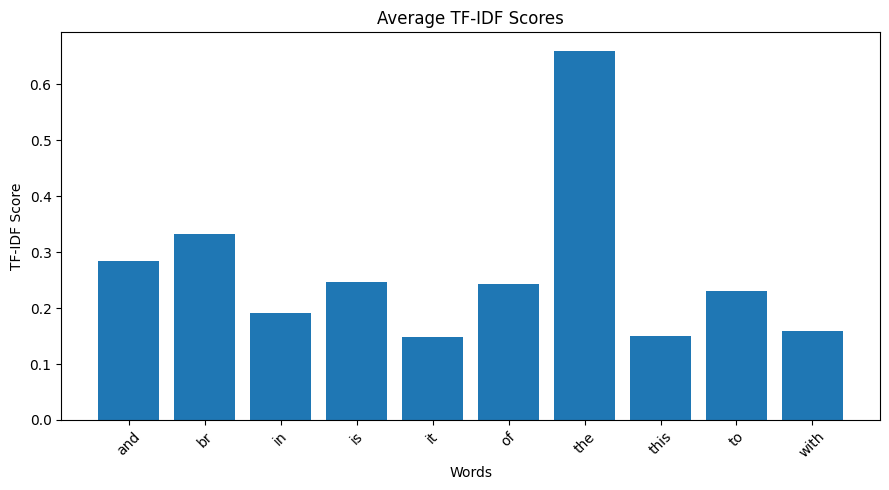


----- MENU -----
1. Show Sample Reviews
2. Show TF-IDF Values
3. Show Feature Words
4. Visualize TF-IDF Scores
5. Exit

Enter your choice: 5

Exiting...


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from IPython.display import display

df = pd.read_csv("IMDB Dataset.csv", on_bad_lines='skip', engine='python')
print(df.head())

text = df["review"].head(5)

vectorizer = TfidfVectorizer(max_features=10)
tfidf_matrix = vectorizer.fit_transform(text)

words = vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=words
)

while True:
    print("\n----- MENU -----")
    print("1. Show Sample Reviews")
    print("2. Show TF-IDF Values")
    print("3. Show Feature Words")
    print("4. Visualize TF-IDF Scores")
    print("5. Exit")

    choice = int(input("\nEnter your choice: "))

    if choice == 1:
        print("\nSample Review:")
        print(text.iloc[0][:500])

    elif choice == 2:
        print("\nTF-IDF Values:")
        display(tfidf_df.round(3).reset_index(drop=True))

    elif choice == 3:
        print("\nFeature Words:")
        print(", ".join(words))

    elif choice == 4:
        scores = tfidf_matrix.toarray().mean(axis=0)

        plt.figure(figsize=(9, 5))
        plt.bar(words, scores)
        plt.title("Average TF-IDF Scores")
        plt.xlabel("Words")
        plt.ylabel("TF-IDF Score")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    elif choice == 5:
        print("\nExiting...")
        break

    else:
        print("\nInvalid choice, try again.")

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

----- MENU -----
1. Show Sample Words
2. Show Unigrams
3. Show Bigrams
4. Show Trigrams
5. Calculate Sequence Probability
6. Visualize N-gram Frequency
7. Exit

Enter your choice: 1

Sample Words:
['one', 'of', 'the', 'other', 'reviewers', 'has', 'mentioned', 'that', 'after', 'watching', 'just', 'oz', 'episode', 'you', 'be', 'hooked', 'they', 'are', 'right', 'as']

----- MENU -----
1. Show Sample Words
2. Show Unigrams
3. Show Bigrams
4. Show Trigrams
5. Calculate Sequence Probability
6. Visualize N-gram Frequency
7. Exit

Enter your choice: 2

Unigrams:
[('the', 8), ('is', 5), ('br', 4), ('of', 3), ('that', 3), (

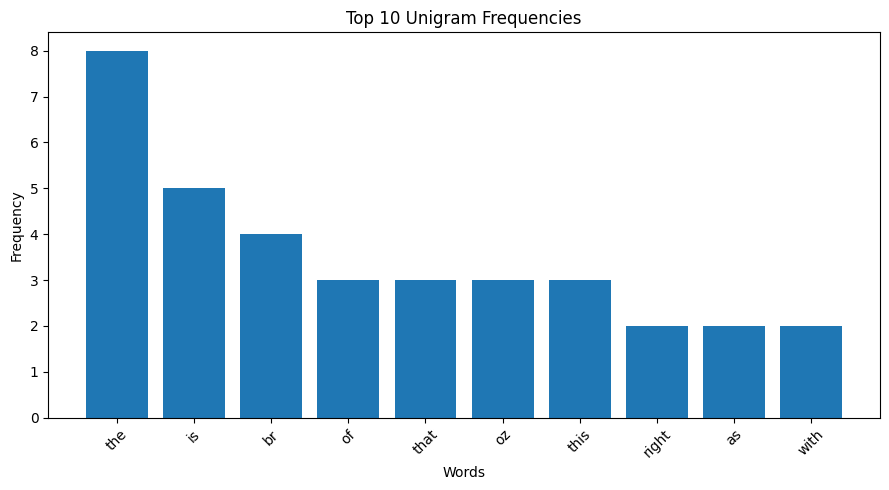


----- MENU -----
1. Show Sample Words
2. Show Unigrams
3. Show Bigrams
4. Show Trigrams
5. Calculate Sequence Probability
6. Visualize N-gram Frequency
7. Exit

Enter your choice: 7

Exiting...


In [ ]:
import pandas as pd
import nltk
import matplotlib.pyplot as plt
from nltk.util import ngrams
from nltk.tokenize import word_tokenize
from collections import Counter

nltk.download('punkt_tab', quiet=True)

df = pd.read_csv("IMDB Dataset.csv", on_bad_lines='skip', engine='python')
print(df.head())

text = str(df["review"].iloc[0]).lower()
words = [w for w in word_tokenize(text) if w.isalpha()][:100]

unigrams = Counter(words)
bigrams = Counter(ngrams(words, 2))
trigrams = Counter(ngrams(words, 3))

total_words = len(words)
vocab_size = len(unigrams)

while True:
    print("\n----- MENU -----")
    print("1. Show Sample Words")
    print("2. Show Unigrams")
    print("3. Show Bigrams")
    print("4. Show Trigrams")
    print("5. Calculate Sequence Probability")
    print("6. Visualize N-gram Frequency")
    print("7. Exit")

    choice = int(input("\nEnter your choice: "))

    if choice == 1:
        print("\nSample Words:")
        print(words[:20])

    elif choice == 2:
        print("\nUnigrams:")
        print(unigrams.most_common(10))

    elif choice == 3:
        print("\nBigrams:")
        print(bigrams.most_common(10))

    elif choice == 4:
        print("\nTrigrams:")
        print(trigrams.most_common(10))

    elif choice == 5:
        sequence = input("\nEnter a sequence of words: ").lower()
        seq_words = [w for w in word_tokenize(sequence) if w.isalpha()]

        if not seq_words:
            print("Please enter valid words.")

        elif len(seq_words) == 1:
            probability = (unigrams[seq_words[0]] + 1) / (total_words + vocab_size)
            print("Sequence Probability:", probability)

        else:
            probability = 1.0

            for i in range(1, len(seq_words)):
                previous = seq_words[i - 1]
                current = seq_words[i]

                numerator = bigrams[(previous, current)] + 1
                denominator = unigrams[previous] + vocab_size

                probability *= numerator / denominator

            print("Sequence Probability:", probability)

    elif choice == 6:
        uni = unigrams.most_common(10)
        labels = [word for word, count in uni]
        values = [count for word, count in uni]

        plt.figure(figsize=(9, 5))
        plt.bar(labels, values)
        plt.title("Top 10 Unigram Frequencies")
        plt.xlabel("Words")
        plt.ylabel("Frequency")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    elif choice == 7:
        print("\nExiting...")
        break

    else:
        print("\nInvalid choice, try again.")



----- MENU -----
1. Show Matrix Shapes (TF-IDF vs LSA)
2. Show Top Words of Each LSA Concept
3. Visualize Explained Variance
4. Visualize Reviews in 2D LSA Space (positive vs negative)
5. Sentiment Classification using LSA Features
6. Predict Sentiment of a New Review
7. Exit

Enter your choice: 1

TF-IDF Matrix Shape: (2000, 5000)
LSA Matrix Shape: (2000, 100)

----- MENU -----
1. Show Matrix Shapes (TF-IDF vs LSA)
2. Show Top Words of Each LSA Concept
3. Visualize Explained Variance
4. Visualize Reviews in 2D LSA Space (positive vs negative)
5. Sentiment Classification using LSA Features
6. Predict Sentiment of a New Review
7. Exit

Enter your choice: 2

Top Words of LSA Concepts:
 Concept                                                            Top Words
       1       movie, film, like, just, good, really, bad, time, story, great
       2      movie, movies, bad, watch, good, really, don, worst, funny, did
       3 bad, film, worst, really, acting, horror, seen, effects, don, st

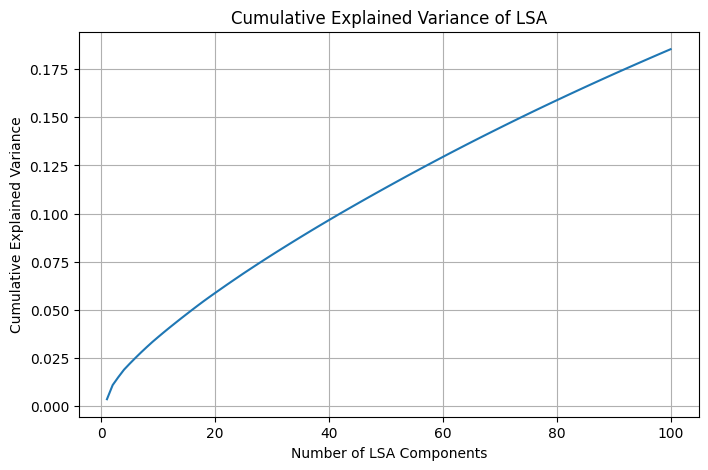

Total explained variance: 18.53 %

----- MENU -----
1. Show Matrix Shapes (TF-IDF vs LSA)
2. Show Top Words of Each LSA Concept
3. Visualize Explained Variance
4. Visualize Reviews in 2D LSA Space (positive vs negative)
5. Sentiment Classification using LSA Features
6. Predict Sentiment of a New Review
7. Exit

Enter your choice: 4


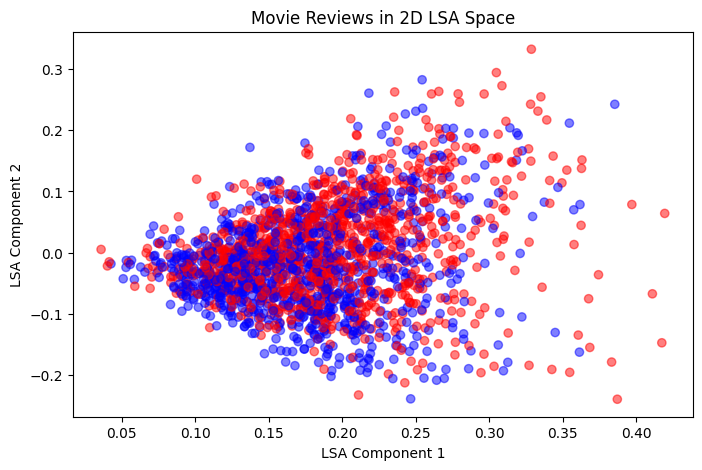

Red = Negative, Blue = Positive

----- MENU -----
1. Show Matrix Shapes (TF-IDF vs LSA)
2. Show Top Words of Each LSA Concept
3. Visualize Explained Variance
4. Visualize Reviews in 2D LSA Space (positive vs negative)
5. Sentiment Classification using LSA Features
6. Predict Sentiment of a New Review
7. Exit

Enter your choice: 5

Accuracy: 83.0 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.83      0.83       203
    Positive       0.82      0.83      0.83       197

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400


----- MENU -----
1. Show Matrix Shapes (TF-IDF vs LSA)
2. Show Top Words of Each LSA Concept
3. Visualize Explained Variance
4. Visualize Reviews in 2D LSA Space (positive vs negative)
5. Sentiment Classification using LSA Features
6. Predict Sentiment of a New Review
7. Exit

Enter your choice: 6

In [ ]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv("IMDB Dataset.csv", on_bad_lines="skip", engine="python")
df = df.dropna(subset=["review", "sentiment"])
df = df.sample(2000, random_state=42).reset_index(drop=True)

df["review"] = df["review"].apply(
    lambda r: re.sub(r"<br\s*/?>", " ", str(r))
)

vectorizer = TfidfVectorizer(max_features=5000, stop_words="english")
tfidf_matrix = vectorizer.fit_transform(df["review"])

lsa = TruncatedSVD(n_components=100, random_state=42)
lsa_matrix = lsa.fit_transform(tfidf_matrix)

labels = df["sentiment"].str.lower().map({
    "negative": 0,
    "positive": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    lsa_matrix,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

feature_names = vectorizer.get_feature_names_out()

while True:
    print("\n----- MENU -----")
    print("1. Show Matrix Shapes (TF-IDF vs LSA)")
    print("2. Show Top Words of Each LSA Concept")
    print("3. Visualize Explained Variance")
    print("4. Visualize Reviews in 2D LSA Space (positive vs negative)")
    print("5. Sentiment Classification using LSA Features")
    print("6. Predict Sentiment of a New Review")
    print("7. Exit")

    choice = input("\nEnter your choice: ")

    if choice == "1":
        print("\nTF-IDF Matrix Shape:", tfidf_matrix.shape)
        print("LSA Matrix Shape:", lsa_matrix.shape)

    elif choice == "2":
        rows = []

        for i, component in enumerate(lsa.components_[:5]):
            top_indices = component.argsort()[-10:][::-1]
            words = [feature_names[j] for j in top_indices]
            rows.append([i + 1, ", ".join(words)])

        result = pd.DataFrame(rows, columns=["Concept", "Top Words"])
        print("\nTop Words of LSA Concepts:")
        print(result.to_string(index=False))

    elif choice == "3":
        cumulative_variance = np.cumsum(lsa.explained_variance_ratio_)

        plt.figure(figsize=(8, 5))
        plt.plot(
            range(1, len(cumulative_variance) + 1),
            cumulative_variance
        )
        plt.title("Cumulative Explained Variance of LSA")
        plt.xlabel("Number of LSA Components")
        plt.ylabel("Cumulative Explained Variance")
        plt.grid(True)
        plt.show()

        print(
            "Total explained variance:",
            round(cumulative_variance[-1] * 100, 2), "%"
        )

    elif choice == "4":
        colors = labels.map({0: "red", 1: "blue"})

        plt.figure(figsize=(8, 5))
        plt.scatter(
            lsa_matrix[:, 0],
            lsa_matrix[:, 1],
            c=colors,
            alpha=0.5
        )
        plt.title("Movie Reviews in 2D LSA Space")
        plt.xlabel("LSA Component 1")
        plt.ylabel("LSA Component 2")
        plt.show()

        print("Red = Negative, Blue = Positive")

    elif choice == "5":
        print(
            "\nAccuracy:",
            round(accuracy_score(y_test, predictions) * 100, 2),
            "%"
        )

        print("\nClassification Report:")
        print(classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["Negative", "Positive"],
            zero_division=0
        ))

    elif choice == "6":
        review = input("\nEnter a movie review: ")
        review = re.sub(r"<br\s*/?>", " ", review)

        review_tfidf = vectorizer.transform([review])
        review_lsa = lsa.transform(review_tfidf)
        prediction = model.predict(review_lsa)[0]

        print(
            "Predicted Sentiment:",
            "Positive" if prediction == 1 else "Negative"
        )

    elif choice == "7":
        print("Exiting...")
        break

    else:
        print("Invalid choice, try again.")


-----Menu-----

1. Scrape Movie Data
2. Show Scraped Data
3. Save Data to CSV
4. Visualize Top 10 Movies
5. Exit
Enter your choice: 1
Data scraped successfully!
Total records: 50

-----Menu-----

1. Scrape Movie Data
2. Show Scraped Data
3. Save Data to CSV
4. Visualize Top 10 Movies
5. Exit
Enter your choice: 2
Rank Peak                        Title    Worldwide gross Year               Ref
   1    1          Avengers: Endgame †     $2,941,375,588 2019   [ # 1 ] [ # 2 ]
   2    1                       Avatar     $2,923,710,708 2009   [ # 3 ] [ # 4 ]
   3    3  Spider-Man: Brand New Day †     $2,517,101,128 2026           [ # 5 ]
   4    3     Avatar: The Way of Water     $2,334,484,620 2022   [ # 6 ] [ # 7 ]
   5    1                      Titanic  T $ 2,257,906,828 1997   [ # 8 ] [ # 9 ]
   6    5                     Ne Zha 2 NZ $ 2,217,758,382 2025 [ # 10 ] [ # 11 ]
   7    3 Star Wars: The Force Awakens     $2,068,223,624 2015 [ # 12 ] [ # 13 ]
   8    4       Avengers: Infinity Wa

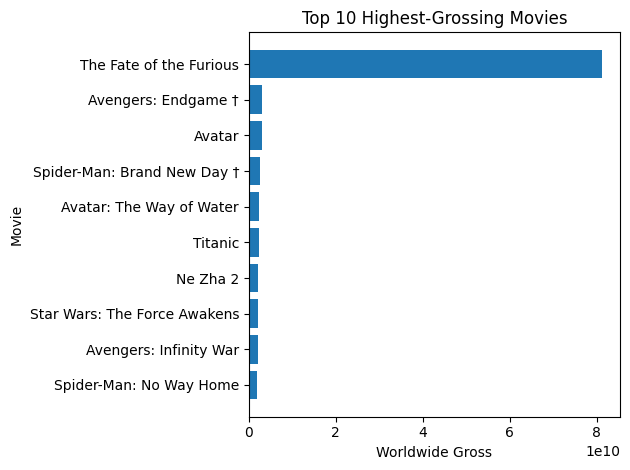


-----Menu-----

1. Scrape Movie Data
2. Show Scraped Data
3. Save Data to CSV
4. Visualize Top 10 Movies
5. Exit
Enter your choice: 5
Program exited.


In [ ]:

import requests
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

movies = []

def scrape_data():
    global movies

    url = "https://en.wikipedia.org/wiki/List_of_highest-grossing_films"
    headers = {"User-Agent": "Mozilla/5.0"}

    response = requests.get(url, headers=headers, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    table = None

    for t in soup.find_all("table", class_="wikitable"):
        if "Worldwide gross" in t.get_text():
            table = t
            break

    if table is None:
        print("Movie table not found.")
        return

    rows = table.find_all("tr")
    headers = [
        cell.get_text(" ", strip=True)
        for cell in rows[0].find_all(["th", "td"])
    ]

    movies = []

    for row in rows[1:]:
        values = [
            cell.get_text(" ", strip=True)
            for cell in row.find_all(["th", "td"])
        ]

        if len(values) == len(headers):
            movies.append(dict(zip(headers, values)))

    print("Data scraped successfully!")
    print("Total records:", len(movies))


while True:
    print("\n-----Menu-----")
    print("\n1. Scrape Movie Data")
    print("2. Show Scraped Data")
    print("3. Save Data to CSV")
    print("4. Visualize Top 10 Movies")
    print("5. Exit")

    choice = input("Enter your choice: ")

    if choice == "1":
        try:
            scrape_data()
        except requests.RequestException as e:
            print("Error fetching webpage:", e)

    elif choice == "2":
        if movies:
            print(pd.DataFrame(movies).head(10).to_string(index=False))
        else:
            print("Scrape data first.")

    elif choice == "3":
        if movies:
            pd.DataFrame(movies).to_csv(
                "scraped_movies.csv", index=False
            )
            print("Data saved to scraped_movies.csv")
        else:
            print("Scrape data first.")

    elif choice == "4":
        if not movies:
            print("Scrape data first.")
            continue

        df = pd.DataFrame(movies)

        title_col = next(
            (c for c in df.columns
             if "title" in c.lower() or "film" in c.lower()),
            None
        )

        gross_col = next(
            (c for c in df.columns if "worldwide gross" in c.lower()),
            None
        )

        if title_col and gross_col:
            df["Gross"] = pd.to_numeric(
                df[gross_col].str.replace(r"[^\d.]", "", regex=True),
                errors="coerce"
            )

            top10 = df.dropna(subset=["Gross"]).nlargest(10, "Gross")

            if top10.empty:
                print("No gross data available to visualize.")
            else:
                plt.barh(top10[title_col], top10["Gross"])
                plt.xlabel("Worldwide Gross")
                plt.ylabel("Movie")
                plt.title("Top 10 Highest-Grossing Movies")
                plt.gca().invert_yaxis()
                plt.tight_layout()
                plt.show()
        else:
            print("Required columns not found.")

    elif choice == "5":
        print("Program exited.")
        break

    else:
        print("Invalid choice.")


